# FakeCatcher baseline — Ciftci et al. [4]
**Biological-signal (PPG) maps classified with a CNN and an SVM**

Pipeline (following Ciftci, Demir & Yin, *FakeCatcher*, IEEE TPAMI 2020):
1. Detect the face, crop the mid-face (cheeks / nose / forehead band).
2. Split it into a **4 × 8 grid = 32 ROIs**.
3. For every ROI take the mean RGB over a window of **ω = 64 samples** and convert it to a **CHROM rPPG signal** (de Haan & Jeanne).
4. Stack the 32 signals into a **PPG map** (32 × 64), plus a second channel with each signal's **power spectrum** → input of shape `2 × 32 × 64`.
5. **CNN** classifies the PPG maps; **SVM** classifies hand-crafted signal features (spectral peak, cross-ROI correlation, L/R symmetry, skew, kurtosis…).
6. Final score = average of CNN and SVM probabilities; per-video score = average over its windows.

> ⚠️ **About the P2datasetFull data:** FakeCatcher measures *heartbeat over time*, so the original method needs **videos**.
> The folders I checked (`train/1`, `train/2`, …) contain **still images**. For images the notebook runs an **image-mode adaptation**: the 64 samples come from scanning each ROI top-to-bottom (spatial colour signal) instead of across frames. It keeps the same map → CNN + SVM structure, but it is *not* a true PPG signal — say so in Chapter 3 if you report it.
> If you drop videos (`.mp4`, `.avi`, …) into the same folder layout, `MODE='auto'` switches to the faithful video pipeline.

## 1. Connect Google Drive

In [11]:
# ML-dataset is SHARED with you, so it won't appear in MyDrive by default.
# One-time fix: open the folder in Google Drive → right-click "ML-dataset" → Organize → Add shortcut → My Drive.
from google.colab import drive
drive.mount('/content/drive')

import os, glob
candidates = (
    glob.glob('/content/drive/MyDrive/ML-dataset/P2datasetFull') +
    glob.glob('/content/drive/MyDrive/*/ML-dataset/P2datasetFull') +
    glob.glob('/content/drive/MyDrive/*/P2datasetFull') +
    glob.glob('/content/drive/.shortcut-targets-by-id/*/ML-dataset/P2datasetFull') +
    glob.glob('/content/drive/.shortcut-targets-by-id/*/P2datasetFull')
)
assert candidates, ("P2datasetFull not found. Add a shortcut of the shared 'ML-dataset' folder to My Drive "
                    "(right-click → Organize → Add shortcut), then re-run this cell.")
DATA_ROOT = candidates[0]
print('Dataset found at:', DATA_ROOT)
print(os.listdir(DATA_ROOT))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset found at: /content/drive/MyDrive/ML-dataset/P2datasetFull
['val1', 'train', 'test1']


## 2. Settings

In [12]:
SPLITS = {'train': 'train', 'val': 'val1', 'test': 'test1'}

# ⚠️ CHECK THIS: which class folder is REAL and which is FAKE in your dataset.
# 0 = real, 1 = fake
CLASS_TO_LABEL = {'1': 0, '2': 1}

MODE = 'auto'          # 'auto' | 'video' | 'image'
N_ROWS, N_COLS = 4, 8  # 32 ROIs, as in FakeCatcher
WIN = 64               # ω: samples per PPG window
FPS_DEFAULT = 30       # used when a video has no FPS metadata
MAX_WINDOWS = 8        # windows per video (video mode)
LOCAL_COPY = True      # copy dataset to Colab's local disk first (much faster than reading from Drive)
SEED = 42

RESULTS_DIR = os.path.join(os.path.dirname(DATA_ROOT), 'P2_results', 'FakeCatcher')
os.makedirs(RESULTS_DIR, exist_ok=True)
print('Results will be saved to:', RESULTS_DIR)

Results will be saved to: /content/drive/MyDrive/ML-dataset/P2_results/FakeCatcher


In [13]:
import shutil, time
if LOCAL_COPY:
    ROOT = '/content/P2datasetFull'
    if not os.path.exists(ROOT):
        t = time.time()
        shutil.copytree(DATA_ROOT, ROOT)
        print(f'Copied to local disk in {time.time()-t:.0f}s')
else:
    ROOT = DATA_ROOT

from collections import Counter
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
VID_EXT = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}

def list_split(split):
    items = []
    for cls, lab in CLASS_TO_LABEL.items():
        d = os.path.join(ROOT, SPLITS[split], cls)
        if not os.path.isdir(d):
            print('⚠️ missing folder:', d); continue
        for f in sorted(os.listdir(d)):
            if os.path.splitext(f)[1].lower() in IMG_EXT | VID_EXT:
                items.append((os.path.join(d, f), lab))
    return items

files = {s: list_split(s) for s in SPLITS}
for s, v in files.items():
    print(f'{s:5s}: {len(v):6d} files  labels={dict(Counter(l for _, l in v))}')

if MODE == 'auto':
    n_vid = sum(os.path.splitext(p)[1].lower() in VID_EXT for p, _ in files['train'])
    MODE = 'video' if n_vid > len(files['train']) / 2 else 'image'
print('MODE =', MODE)

Copied to local disk in 205s
train:   6257 files  labels={0: 3207, 1: 3050}
val  :   6221 files  labels={0: 3150, 1: 3071}
test :   6246 files  labels={0: 3171, 1: 3075}
MODE = image


## 3. PPG signal extraction and PPG maps

In [14]:
import cv2, threading
import numpy as np
from scipy.signal import butter, filtfilt, welch, detrend
from scipy.stats import skew, kurtosis

_tl = threading.local()
HAS_CASCADE = hasattr(cv2, 'CascadeClassifier') and hasattr(cv2, 'data')
if not HAS_CASCADE:
    print('⚠️ OpenCV Haar cascade unavailable — whole image will be used as the face region.')

def _cascade():
    if not hasattr(_tl, 'c'):
        _tl.c = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    return _tl.c

def detect_face(bgr):
    if not HAS_CASCADE:
        return None
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    faces = _cascade().detectMultiScale(gray, 1.1, 5, minSize=(30, 30))
    return None if len(faces) == 0 else max(faces, key=lambda b: b[2] * b[3])

def midface_crop(bgr, box, size):
    # Keep the skin band (forehead-to-mouth, inner cheeks); drop hair and background.
    h, w = bgr.shape[:2]
    x, y, bw, bh = (0, 0, w, h) if box is None else box
    x0, x1 = int(x + 0.15 * bw), int(x + 0.85 * bw)
    y0, y1 = int(y + 0.20 * bh), int(y + 0.85 * bh)
    crop = bgr[max(y0, 0):min(y1, h), max(x0, 0):min(x1, w)]
    if crop.size == 0:
        crop = bgr
    return cv2.resize(crop, size)          # size = (width, height)

def chrom(rgb):
    # CHROM rPPG (de Haan & Jeanne 2013). rgb: (T, 3) in R,G,B order.
    rgb = rgb / (rgb.mean(0, keepdims=True) + 1e-8)
    X = 3 * rgb[:, 0] - 2 * rgb[:, 1]
    Y = 1.5 * rgb[:, 0] + rgb[:, 1] - 1.5 * rgb[:, 2]
    return X - (X.std() / (Y.std() + 1e-8)) * Y

def bandpass(sig, fs, lo=0.7, hi=4.0, order=3):   # 42–240 bpm heart-rate band
    nyq = fs / 2
    hi = min(hi, 0.95 * nyq)
    if lo >= hi or len(sig) <= 30:
        return sig - sig.mean()
    b, a = butter(order, [lo / nyq, hi / nyq], btype='band')
    return filtfilt(b, a, sig)

def znorm(x):
    x = x - x.mean()
    return x / (x.std() + 1e-8)

def psd_vec(sig, fs, n):
    f, p = welch(sig, fs=fs, nperseg=min(len(sig), n))
    p = np.interp(np.linspace(f[0], f[-1], n), f, p)
    return p / (p.max() + 1e-8)

def build_map(traces, fs, temporal=True):
    # traces: (R, T, 3) mean RGB per ROI per sample -> PPG map (2, R, T): [signal, spectrum]
    sig, spec = [], []
    for tr in traces:
        s = chrom(tr)
        s = bandpass(s, fs) if temporal else detrend(s)
        s = znorm(s)
        sig.append(s)
        spec.append(psd_vec(s, fs, len(s)))
    return np.stack([np.array(sig), np.array(spec)]).astype(np.float32)

def grid_means(rgb):
    # (H, W, 3) -> (N_ROWS*N_COLS, 3) mean colour per ROI
    H, W = rgb.shape[:2]
    ch, cw = H // N_ROWS, W // N_COLS
    return rgb[:ch * N_ROWS, :cw * N_COLS].reshape(N_ROWS, ch, N_COLS, cw, 3).mean((1, 3)).reshape(-1, 3)

def video_maps(path):
    # Faithful FakeCatcher: ROI colour over TIME, sliding windows of WIN frames.
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps < 1 or fps > 120:
        fps = FPS_DEFAULT
    traces, box, i = [], None, 0
    while len(traces) < WIN * MAX_WINDOWS:
        ok, fr = cap.read()
        if not ok:
            break
        if i % 10 == 0 or box is None:          # re-detect every 10 frames
            nb = detect_face(fr)
            box = nb if nb is not None else box
        crop = midface_crop(fr, box, (N_COLS * 16, N_ROWS * 16))
        traces.append(grid_means(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB).astype(np.float32)))
        i += 1
    cap.release()
    if len(traces) < WIN:
        return []
    tr = np.stack(traces)                        # (T, R, 3)
    return [build_map(tr[s:s + WIN].transpose(1, 0, 2), fps, True)
            for s in range(0, len(tr) - WIN + 1, WIN)]

def image_map(path):
    # Image-mode adaptation: each ROI scanned top-to-bottom gives a WIN-sample spatial colour signal.
    bgr = cv2.imread(path)
    if bgr is None:
        return None
    crop = midface_crop(bgr, detect_face(bgr), (N_COLS * 16, N_ROWS * WIN))
    rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB).astype(np.float32)
    cells = rgb.reshape(N_ROWS, WIN, N_COLS, 16, 3).mean(3)          # (rows, WIN, cols, 3)
    traces = cells.transpose(0, 2, 1, 3).reshape(N_ROWS * N_COLS, WIN, 3)
    return build_map(traces, fs=float(WIN), temporal=False)

def handcrafted(m, fs):
    # Signal features for the SVM branch.
    sig, spec = m[0], m[1]
    T = sig.shape[1]
    freqs = np.linspace(0, fs / 2, T)
    peak = freqs[spec.argmax(1)]
    with np.errstate(invalid='ignore', divide='ignore'):
        C = np.corrcoef(sig)
    cc = np.nan_to_num(C[np.triu_indices_from(C, 1)])
    g = sig.reshape(N_ROWS, N_COLS, T)
    left, right = g[:, :N_COLS // 2].reshape(-1, T).mean(0), g[:, N_COLS // 2:].reshape(-1, T).mean(0)
    mean_sig = sig.mean(0)
    feats = [
        skew(sig, axis=1).mean(), skew(sig, axis=1).std(),
        kurtosis(sig, axis=1).mean(), kurtosis(sig, axis=1).std(),
        peak.mean(), peak.std(),
        cc.mean(), cc.std(), cc.min(), *np.percentile(cc, [10, 50, 90]),
        spec.max(1).mean(), (spec.max(1) / (spec.sum(1) + 1e-8)).mean(),   # spectral concentration (SNR proxy)
        mean_sig.std(), np.abs(np.diff(mean_sig)).mean(),
        np.corrcoef(left, right)[0, 1] if left.std() > 0 and right.std() > 0 else 0.0,  # L/R symmetry
    ]
    return np.nan_to_num(np.array(feats, dtype=np.float32))

## 4. Extract PPG maps for every split (cached to Drive)

In [15]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

def _work(arg):
    p, l = arg
    try:
        if MODE == 'video':
            ms = video_maps(p)
        else:
            m = image_map(p)
            ms = [] if m is None else [m]
    except Exception as e:
        print('skip', p, e); ms = []
    return p, l, ms

def extract(items):
    X, y, g = [], [], []
    with ThreadPoolExecutor(8) as ex:
        for p, l, ms in tqdm(ex.map(_work, items), total=len(items)):
            for m in ms:
                X.append(m); y.append(l); g.append(p)
    if len(X) == 0:
        return np.empty((0, 2, 32, 64), dtype=np.float32), np.array([], dtype=np.int64), np.array([], dtype=object)
    return np.stack(X), np.array(y), np.array(g)

data = {}
for s in SPLITS:
    cache = os.path.join(RESULTS_DIR, f'ppgmaps_{MODE}_{s}.npz')
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        data[s] = (z['X'], z['y'], z['g'])
        print(f'{s}: loaded cache')
    else:
        data[s] = extract(files[s])
        np.savez_compressed(cache, X=data[s][0], y=data[s][1], g=data[s][2])
    print(f'{s}: maps {data[s][0].shape}, labels {dict(Counter(data[s][1].tolist()))}')

train: loaded cache
train: maps (6257, 2, 32, 64), labels {0: 3207, 1: 3050}
val: loaded cache
val: maps (6221, 2, 32, 64), labels {0: 3150, 1: 3071}


  0%|          | 0/6246 [00:00<?, ?it/s]

test: maps (6246, 2, 32, 64), labels {0: 3171, 1: 3075}


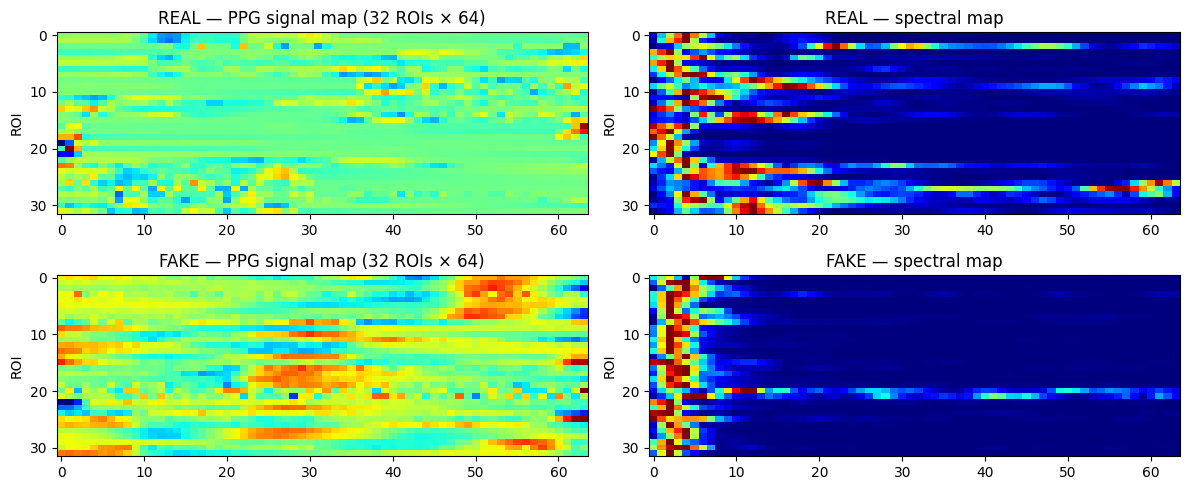

In [16]:
# Look at one real and one fake PPG map
import matplotlib.pyplot as plt
Xtr, ytr, _ = data['train']
fig, ax = plt.subplots(2, 2, figsize=(12, 5))
for r, lab in enumerate([0, 1]):
    m = Xtr[np.where(ytr == lab)[0][0]]
    ax[r, 0].imshow(m[0], aspect='auto', cmap='jet'); ax[r, 0].set_title(f"{['REAL','FAKE'][lab]} — PPG signal map (32 ROIs × {WIN})")
    ax[r, 1].imshow(m[1], aspect='auto', cmap='jet'); ax[r, 1].set_title(f"{['REAL','FAKE'][lab]} — spectral map")
    for a in ax[r]: a.set_ylabel('ROI')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'ppg_map_examples.png'), dpi=150); plt.show()

## 5. SVM on PPG signal features

In [17]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, PredefinedSplit

FS_EFF = FPS_DEFAULT if MODE == 'video' else float(WIN)
F = {s: np.stack([handcrafted(m, FS_EFF) for m in tqdm(data[s][0], desc=s)]) for s in SPLITS}

X_tv = np.vstack([F['train'], F['val']])
y_tv = np.concatenate([data['train'][1], data['val'][1]])
ps = PredefinedSplit(np.r_[np.full(len(F['train']), -1), np.zeros(len(F['val']))])   # tune on val1

svm = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED)),
    {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.01, 0.1]},
    cv=ps, scoring='f1', n_jobs=-1, verbose=1)
svm.fit(X_tv, y_tv)
print('Best SVM params:', svm.best_params_, ' val F1 =', round(svm.best_score_, 4))

train:   0%|          | 0/6257 [00:00<?, ?it/s]

val:   0%|          | 0/6221 [00:00<?, ?it/s]

test:   0%|          | 0/6246 [00:00<?, ?it/s]

Fitting 1 folds for each of 12 candidates, totalling 12 fits
Best SVM params: {'svc__C': 100, 'svc__gamma': 0.01}  val F1 = 0.6996


## 6. CNN on PPG maps

In [18]:
import torch, torch.nn as nn, random
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score

torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', dev)

class PPGNet(nn.Module):
    def __init__(self):
        super().__init__()
        def blk(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                 nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(blk(2, 32), blk(32, 64), blk(64, 128))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(128, 1))
    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

def loader(s, shuffle):
    X, y, _ = data[s]
    return DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y.astype(np.float32))),
                      batch_size=128, shuffle=shuffle, num_workers=2)

@torch.no_grad()
def cnn_predict(model, s):
    model.eval()
    return np.concatenate([torch.sigmoid(model(xb.to(dev))).cpu().numpy() for xb, _ in loader(s, False)])

model = PPGNet().to(dev)
y_train = data['train'][1]
pos_weight = torch.tensor([(y_train == 0).sum() / max((y_train == 1).sum(), 1)], device=dev)
crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
EPOCHS, PATIENCE = 40, 8
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
best_auc, bad, history = -1, 0, []
ckpt = os.path.join(RESULTS_DIR, f'fakecatcher_cnn_{MODE}.pt')

for ep in range(1, EPOCHS + 1):
    model.train(); tot = 0
    for xb, yb in loader('train', True):
        xb, yb = xb.to(dev), yb.to(dev)
        xb = torch.roll(xb, shifts=random.randint(0, WIN - 1), dims=3)   # augmentation: circular time shift
        xb = xb + 0.05 * torch.randn_like(xb)                           # augmentation: noise
        opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        tot += loss.item() * len(xb)
    sched.step()
    val_auc = roc_auc_score(data['val'][1], cnn_predict(model, 'val'))
    history.append((ep, tot / len(y_train), val_auc))
    print(f'epoch {ep:2d}  loss {tot/len(y_train):.4f}  val AUC {val_auc:.4f}')
    if val_auc > best_auc:
        best_auc, bad = val_auc, 0
        torch.save(model.state_dict(), ckpt)
    else:
        bad += 1
        if bad >= PATIENCE:
            print('Early stopping'); break

model.load_state_dict(torch.load(ckpt, map_location=dev))
print('Best val AUC:', round(best_auc, 4), '→ saved', ckpt)

Device: cuda
epoch  1  loss 0.6593  val AUC 0.7150
epoch  2  loss 0.6305  val AUC 0.6952
epoch  3  loss 0.6214  val AUC 0.7237
epoch  4  loss 0.6105  val AUC 0.7204
epoch  5  loss 0.6001  val AUC 0.7226
epoch  6  loss 0.5808  val AUC 0.7298
epoch  7  loss 0.5683  val AUC 0.7277
epoch  8  loss 0.5460  val AUC 0.7153
epoch  9  loss 0.5318  val AUC 0.6773
epoch 10  loss 0.5075  val AUC 0.7059
epoch 11  loss 0.4652  val AUC 0.7128
epoch 12  loss 0.4236  val AUC 0.6881
epoch 13  loss 0.3938  val AUC 0.6807
epoch 14  loss 0.3440  val AUC 0.6886
Early stopping
Best val AUC: 0.7298 → saved /content/drive/MyDrive/ML-dataset/P2_results/FakeCatcher/fakecatcher_cnn_image.pt


## 7. Test-set evaluation (CNN, SVM, and CNN+SVM fusion)

,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
FakeCatcher CNN,0.6230,0.6805,0.4413,0.5354,0.7148
FakeCatcher SVM,0.6463,0.6128,0.7652,0.6805,0.7112
FakeCatcher CNN+SVM,0.6551,0.6694,0.5919,0.6282,0.7286


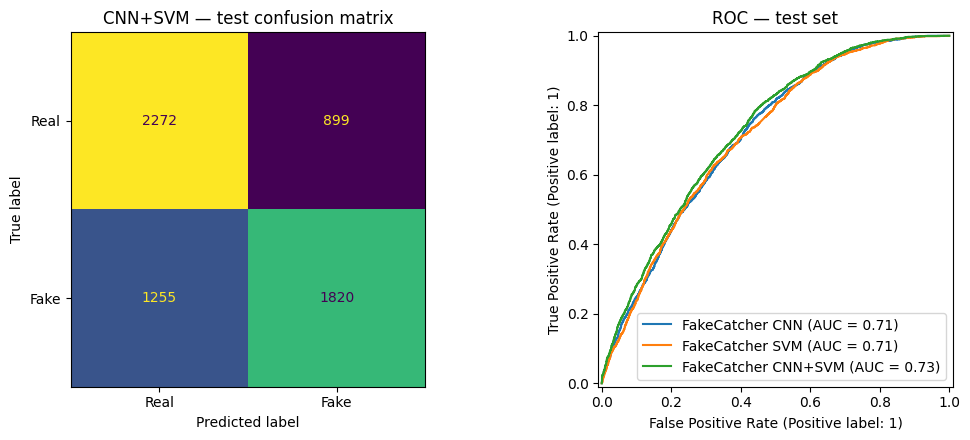

Saved results, plots and models to /content/drive/MyDrive/ML-dataset/P2_results/FakeCatcher


In [19]:
import pandas as pd, joblib
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

def per_file(prob, groups, labels):
    # Average window scores per video/image (FakeCatcher's video-level aggregation).
    df = pd.DataFrame({'g': groups, 'p': prob, 'y': labels}).groupby('g').agg(p=('p', 'mean'), y=('y', 'first'))
    return df['p'].values, df['y'].values.astype(int)

def metrics(name, prob, y, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred, zero_division=0), 'F1': f1_score(y, pred, zero_division=0),
            'AUC': roc_auc_score(y, prob)}

_, y_test, g_test = data['test']
p_cnn = cnn_predict(model, 'test')
p_svm = svm.predict_proba(F['test'])[:, 1]
p_fuse = (p_cnn + p_svm) / 2

rows, probs = [], {}
for name, p in [('FakeCatcher CNN', p_cnn), ('FakeCatcher SVM', p_svm), ('FakeCatcher CNN+SVM', p_fuse)]:
    pf, yf = per_file(p, g_test, y_test)
    probs[name] = (pf, yf)
    rows.append(metrics(name, pf, yf))
res = pd.DataFrame(rows).set_index('Model').round(4)
display(res)
res.to_csv(os.path.join(RESULTS_DIR, f'fakecatcher_test_results_{MODE}.csv'))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
pf, yf = probs['FakeCatcher CNN+SVM']
ConfusionMatrixDisplay(confusion_matrix(yf, (pf >= 0.5).astype(int)), display_labels=['Real', 'Fake']).plot(ax=ax[0], colorbar=False)
ax[0].set_title('CNN+SVM — test confusion matrix')
for name, (pf, yf) in probs.items():
    RocCurveDisplay.from_predictions(yf, pf, name=name, ax=ax[1])
ax[1].set_title('ROC — test set')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, f'fakecatcher_eval_{MODE}.png'), dpi=150); plt.show()

joblib.dump(svm.best_estimator_, os.path.join(RESULTS_DIR, f'fakecatcher_svm_{MODE}.joblib'))
print('Saved results, plots and models to', RESULTS_DIR)